# TMDB Movie Data Analysis
Modular pipeline: fetch → clean → analyze → visualize. All logic lives in `src/`.

In [1]:
import sys
import os
import pandas as pd

# Make sure the project runs correctly from the notebooks or project root folder
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.path.abspath("."))

# Import functions to collect, clean, and validate movie data
from src.fetch_movies import fetch_movies
from src.clean_movies import clean_dataframe
from src.validate_clean_data import save_clean_data

# Import functions to explore the dataset and analyze movie performance
from src.explore_movies import print_basic_info
from src.analyze_kpis import rank_movies
from src.compare_franchises import compare_franchise_vs_standalone
from src.analyze_franchises import analyze_franchise_performance
from src.analyze_directors import analyze_director_performance

# Import functions to find movies featuring specific actors (Required searches)
from src.search_bruce_willis import find_bruce_willis
from src.search_uma_thurman import find_uma_thurman

# Import functions to create charts and visualize movie trends
from src.visualize import (
    plot_revenue_vs_budget,
    plot_top_10_revenue,
    plot_roi_by_genre,
    plot_popularity_vs_rating,
    plot_franchise_vs_standalone,
)

# Load environment variables and get the TMDB API key
from dotenv import load_dotenv
load_dotenv()

API_KEY = os.getenv("TMDB_API_KEY")

## 1. Fetch

In [2]:
movie_id = [
    0, 299534, 19995, 140607, 299536, 597, 135397,
    420818, 24428, 168259, 99861, 284054, 12445,
    181808, 330457, 351286, 109445, 321612, 260513
]

try:
    raw_movies = fetch_movies(movie_id, API_KEY)
    print(f"Loaded {len(raw_movies)} movies.")
except RuntimeError as e:
    print(f"Fetch failed: {e}")
    raw_movies = []

Failed: 0 (Status: 404 Not Found)
Fetched: Avengers: Endgame
Fetched: Avatar
Fetched: Star Wars: The Force Awakens
Fetched: Avengers: Infinity War
Fetched: Titanic
Fetched: Jurassic World
Fetched: The Lion King
Fetched: The Avengers
Fetched: Furious 7
Fetched: Avengers: Age of Ultron
Fetched: Black Panther
Fetched: Harry Potter and the Deathly Hallows: Part 2
Fetched: Star Wars: The Last Jedi
Fetched: Frozen II
Fetched: Jurassic World: Fallen Kingdom
Fetched: Frozen
Fetched: Beauty and the Beast
Fetched: Incredibles 2
Saved raw data to: data/raw\tmdb_movies_raw.csv
Raw shape: 18 rows x 28 columns
Loaded 18 movies.


## 2. Clean & Save

In [3]:
df = clean_dataframe(raw_movies)
save_clean_data(df)
print_basic_info(df)

Saved cleaned data to: data/processed\tmdb_movies_clean.csv
Total movies: 18
--- First 5 Movies ---
                          title  release_year  budget_musd  revenue_musd  \
0             Avengers: Endgame          2019        356.0   2938.567784   
1                        Avatar          2009        237.0   2923.706026   
2  Star Wars: The Force Awakens          2015        245.0   2068.223624   
3        Avengers: Infinity War          2018        300.0   2052.415039   
4                       Titanic          1997        200.0   2264.162353   

   vote_average  
0         8.247  
1         7.611  
2         7.240  
3         8.245  
4         7.901  

--- Numeric Summary ---
       budget_musd  revenue_musd  runtime  vote_average
count        18.00         18.00    18.00         18.00
mean        213.78       1699.66   138.00          7.40
std          61.96        539.11    23.85          0.53
min         125.00       1243.23   102.00          6.52
25%         162.50       1336.

## 3. Rankings

In [4]:
print("Top 5 Revenue:")
display(rank_movies(df, "revenue_musd", top_n=5))

print("\nTop 5 ROI (Budget >= $10M):")
display(rank_movies(df, "roi", top_n=5, min_budget=10))

Top 5 Revenue:


,title,revenue_musd
0,Avengers: Endgame,2938.567784
1,Avatar,2923.706026
4,Titanic,2264.162353
2,Star Wars: The Force Awakens,2068.223624
3,Avengers: Infinity War,2052.415039



Top 5 ROI (Budget >= $10M):


,title,roi
1,Avatar,12.336312
4,Titanic,11.320812
5,Jurassic World,11.143583
11,Harry Potter and the Deathly Hallows: Part 2,10.732090
13,Frozen II,9.691223


## 4. Searches & Comparison

In [5]:
# search 1: Bruce Willis movies
print("Bruce Willis movies:")
display(find_bruce_willis(df))

# search 2: Uma Thurman movies directed by Quentin Tarantino
print("\nUma Thurman + Quentin Tarantino:")
display(find_uma_thurman(df))

# Franchise vs standalone comparison
print("\nFranchise vs Standalone:")
display(compare_franchise_vs_standalone(df))

Bruce Willis movies:


,backdrop_path,belongs_to_collection,genres,id,origin_country,original_language,overview,popularity,poster_path,production_companies,...,cast,cast_size,director,crew_size,budget_musd,revenue_musd,profit_musd,roi,is_franchise,release_year



Uma Thurman + Quentin Tarantino:


,backdrop_path,belongs_to_collection,genres,id,origin_country,original_language,overview,popularity,poster_path,production_companies,...,cast,cast_size,director,crew_size,budget_musd,revenue_musd,profit_musd,roi,is_franchise,release_year



Franchise vs Standalone:


,Movies,Mean_Revenue,Median_ROI,Mean_Budget,Mean_Popularity,Mean_Rating
is_franchise,,,,,,
False,2,1765.14,9.62,180.0,32.27,7.44
True,16,1691.47,7.84,218.0,37.41,7.39


## 5. Deep Dives

In [6]:
print("Top Franchises by Revenue:")
display(analyze_franchise_performance(df))

print("\nTop Directors by Revenue:")
display(analyze_director_performance(df))

Top Franchises by Revenue:


,Movies,Total_Budget,Mean_Budget,Total_Revenue,Mean_Revenue,Mean_Rating
belongs_to_collection,,,,,,
The Avengers Collection,4,1111.0,277.75,7915.20,1978.80,7.96
Star Wars Collection,2,545.0,272.50,3402.63,1701.32,6.99
Jurassic Park Collection,2,320.0,160.00,2982.01,1491.00,6.61
Avatar Collection,1,237.0,237.00,2923.71,2923.71,7.61
Frozen Collection,2,300.0,150.00,2727.90,1363.95,7.23
The Lion King (Reboot) Collection,1,260.0,260.00,1662.02,1662.02,7.09
The Fast and the Furious Collection,1,190.0,190.00,1515.40,1515.40,7.21
Black Panther Collection,1,200.0,200.00,1349.93,1349.93,7.36
Harry Potter Collection,1,125.0,125.00,1341.51,1341.51,8.08



Top Directors by Revenue:


,Total_Movies,Total_Revenue,Mean_Rating
director,,,
James Cameron,2,5187.87,7.76
Anthony Russo,2,4990.98,8.25
Joss Whedon,2,2924.22,7.68
J.J. Abrams,1,2068.22,7.24
Colin Trevorrow,1,1671.54,6.70
Jon Favreau,1,1662.02,7.09
James Wan,1,1515.40,7.21
Jennifer Lee,1,1453.68,7.22
Ryan Coogler,1,1349.93,7.36


## 6. Visualizations

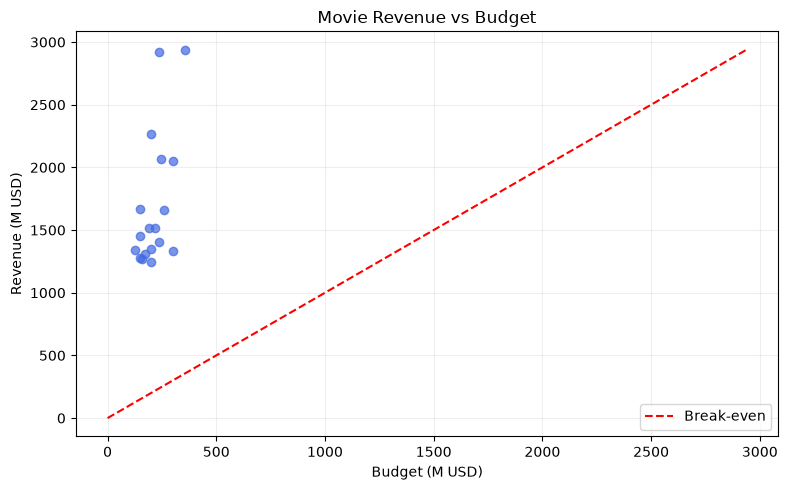

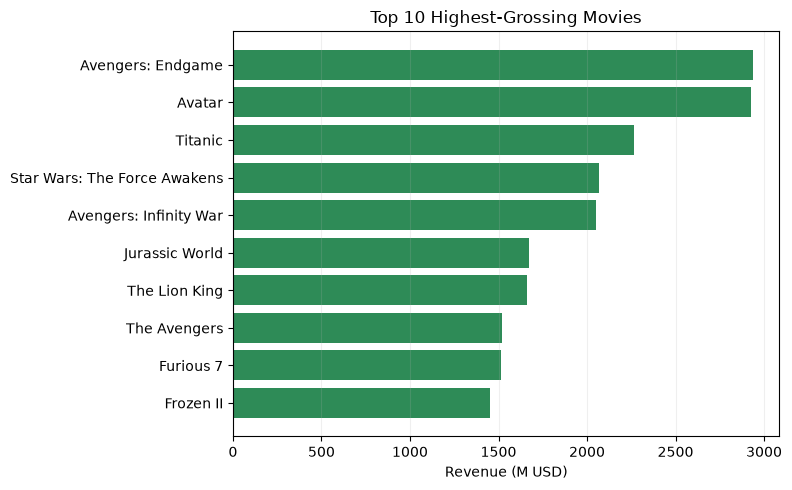

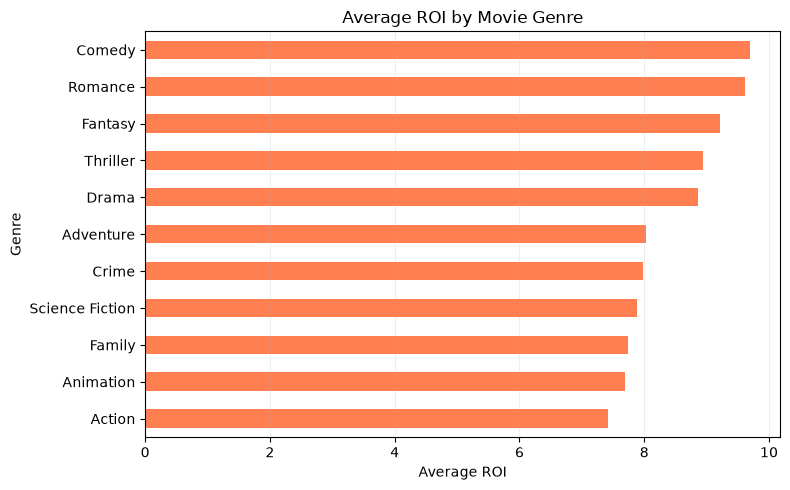

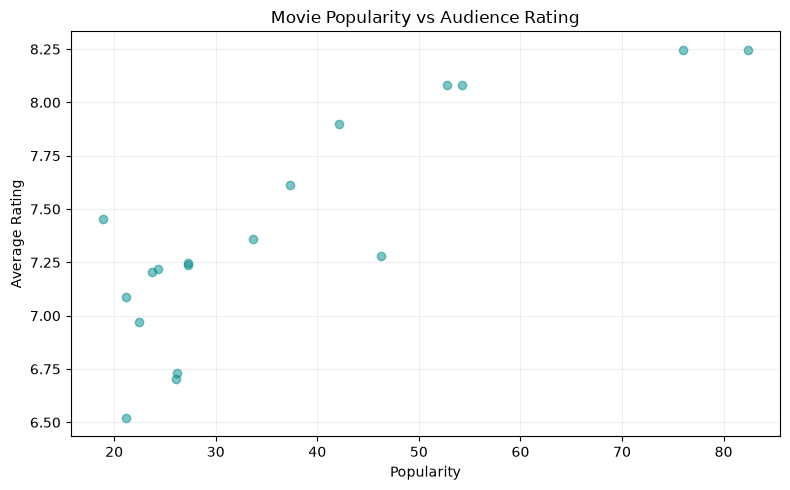

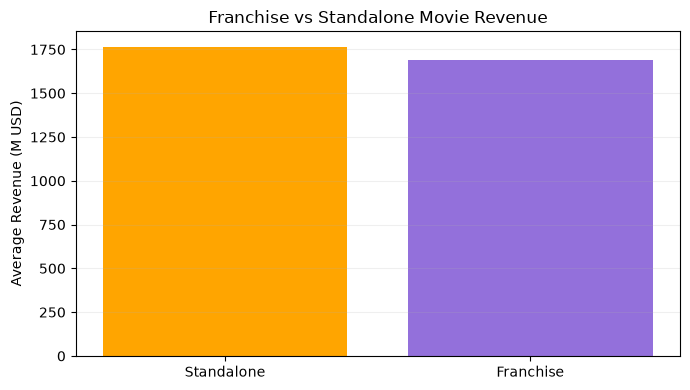

In [7]:
plot_revenue_vs_budget(df)
plot_top_10_revenue(df)
plot_roi_by_genre(df)
plot_popularity_vs_rating(df)
plot_franchise_vs_standalone(df)